# 미니프로젝트: 결측치·이상치·클래스 불균형 처리 (Vibe Coding)

#### <목표>
오늘 배운 **결측치/이상치 처리, Under/Oversampling, SVDD**를 **통신사 고객 이탈(Customer Churn) 데이터셋**에 적용해 봅니다.

**Cursor AI**를 활용하여 각 단계의 코드를 직접 생성하고 실행해 보세요.

#### <데이터셋 소개>
- Telco Customer Churn (통신사 고객 이탈 데이터)
- 고객의 인적사항, 가입 서비스, 요금·계약 정보와 이탈(Churn) 여부를 담은 데이터

| 변수명 | 설명 |
|:---:|:---|
| gender, SeniorCitizen, Partner, Dependents | 고객 인적사항 |
| tenure | 가입 개월 수 |
| PhoneService, MultipleLines, InternetService 등 | 가입 서비스 종류 |
| Contract, PaperlessBilling, PaymentMethod | 계약/결제 정보 |
| MonthlyCharges, TotalCharges | 월/누적 요금 |
| Churn | 이탈 여부 (Yes: 이탈, No: 유지) |

#### <실습 태스크>
| 태스크 | 타겟 변수 | 설명 |
|:---:|:---:|:---|
| 분류 | `Churn` | 고객 정보로 이탈 여부 예측 |

1. 각 섹션의 **과제**를 읽고, 어떤 고민/결정이 필요한지 먼저 생각해 봅니다.
2. 빈 코드 셀을 클릭한 후 Cursor AI 채팅창을 엽니다.
3. 막막한 부분은 AI와 상의해서 방법을 정하고, 그 방법으로 프롬프트를 작성합니다.
4. 생성된 코드를 실행하고 결과를 확인합니다.

## 0) 분석 준비

- `dataset/day4_miniproject.csv` 파일을 사용하기
- 타겟 변수: `Churn` (No: 유지, Yes: 이탈)

**[과제]** 써니는 통신사 고객 이탈 데이터를 분석하게 되었습니다. 분석에 필요한 라이브러리를 호출하고 데이터를 불러와 구조를 확인하는 코드를 AI와 상의해서 작성하세요.

In [34]:
# 주요 라이브러리
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 그래프 스타일 (선택)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 데이터 불러오기
df = pd.read_csv("dataset/day4_miniproject.csv")

# 타겟 변수
TARGET = "Churn"  # No: 유지, Yes: 이탈

# 기본 구조 확인
print("데이터 크기:", df.shape)
print("\n컬럼 목록:")
print(df.columns.tolist())
print("\n데이터 타입:")
print(df.dtypes)
print("\n상위 5행:")
display(df.head())
print("\n기본 통계:")
display(df.describe(include="all"))
print(f"\n타겟 변수 '{TARGET}' 분포:")
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

데이터 크기: (7043, 20)

컬럼 목록:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

데이터 타입:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure              float64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

상위 5행:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



기본 통계:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043.000000,7043,7043,6832.000000,7043,7043,6903,7043,7043,7043,7043,7043,7043,7043,7043,6832,6832.000000,7032.000000,7043
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,3555,NaN,3641,4933,NaN,6361,3390,3033,3498,3088,3095,3473,2810,2785,3875,4171,2296,NaN,NaN,5174
mean,NaN,0.162147,NaN,NaN,32.376903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.758255,2283.300441,NaN
std,NaN,0.368612,NaN,NaN,24.570605,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.077758,2266.771362,NaN
min,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.587500,401.450000,NaN
50%,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN



타겟 변수 'Churn' 분포:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


## 1) 데이터 탐색 (EDA)

### 1-1) 기본 EDA 진행

**[과제]** 써니는 데이터 분석 전, 데이터의 구조적 및 통계적 정보가 궁금해졌습니다. AI와 상의하여 관련 코드를 작성하고 분석해보세요.

In [35]:
# TotalCharges 숫자 변환 (빈 문자열 → NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

TARGET = "Churn"

print("=" * 50)
print("1. 데이터 크기")
print("=" * 50)
print(f"행: {df.shape[0]:,}, 열: {df.shape[1]}")

print("\n" + "=" * 50)
print("2. 컬럼 타입 (info)")
print("=" * 50)
df.info()

print("\n" + "=" * 50)
print("3. 수치형 기술통계")
print("=" * 50)
display(df.describe())

print("\n" + "=" * 50)
print("4. 범주형 기술통계")
print("=" * 50)
display(df.describe(include=["object", "category"]))

print("\n" + "=" * 50)
print("5. 결측치")
print("=" * 50)
missing = df.isna().sum()
display(missing[missing > 0].to_frame("결측 개수"))

print("\n" + "=" * 50)
print("6. 범주형 변수별 고유값 개수")
print("=" * 50)
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
# SeniorCitizen은 0/1 이지만 범주로 보는 경우가 많음
cat_cols = ["SeniorCitizen"] + [c for c in cat_cols if c != "SeniorCitizen"]
cat_cols = list(dict.fromkeys(cat_cols))  # 중복 제거

unique_summary = pd.DataFrame({
    "고유값 수": [df[col].nunique() for col in cat_cols],
    "값 목록": [df[col].unique().tolist() for col in cat_cols]
}, index=cat_cols)
display(unique_summary)

1. 데이터 크기
행: 7,043, 열: 20

2. 컬럼 타입 (info)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            6832 non-null   float64
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   6903 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16 

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,6832.000000,6832.000000,7032.000000
mean,0.162147,32.376903,64.758255,2283.300441
std,0.368612,24.570605,30.077758,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000



4. 범주형 기술통계


,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,6903,7043,7043,7043,7043,7043,7043,7043,7043,6832,7043
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3555,3641,4933,6361,3390,3033,3498,3088,3095,3473,2810,2785,3875,4171,2296,5174



5. 결측치


,결측 개수
tenure,211
InternetService,140
PaymentMethod,211
MonthlyCharges,211
TotalCharges,11



6. 범주형 변수별 고유값 개수


,고유값 수,값 목록
SeniorCitizen,2,"[0, 1]"
gender,2,"[Female, Male]"
Partner,2,"[Yes, No]"
Dependents,2,"[No, Yes]"
PhoneService,2,"[No, Yes]"
MultipleLines,3,"[No phone service, No, Yes]"
InternetService,3,"[DSL, Fiber optic, No, nan]"
OnlineSecurity,3,"[No, Yes, No internet service]"
OnlineBackup,3,"[Yes, No, No internet service]"
DeviceProtection,3,"[No, Yes, No internet service]"


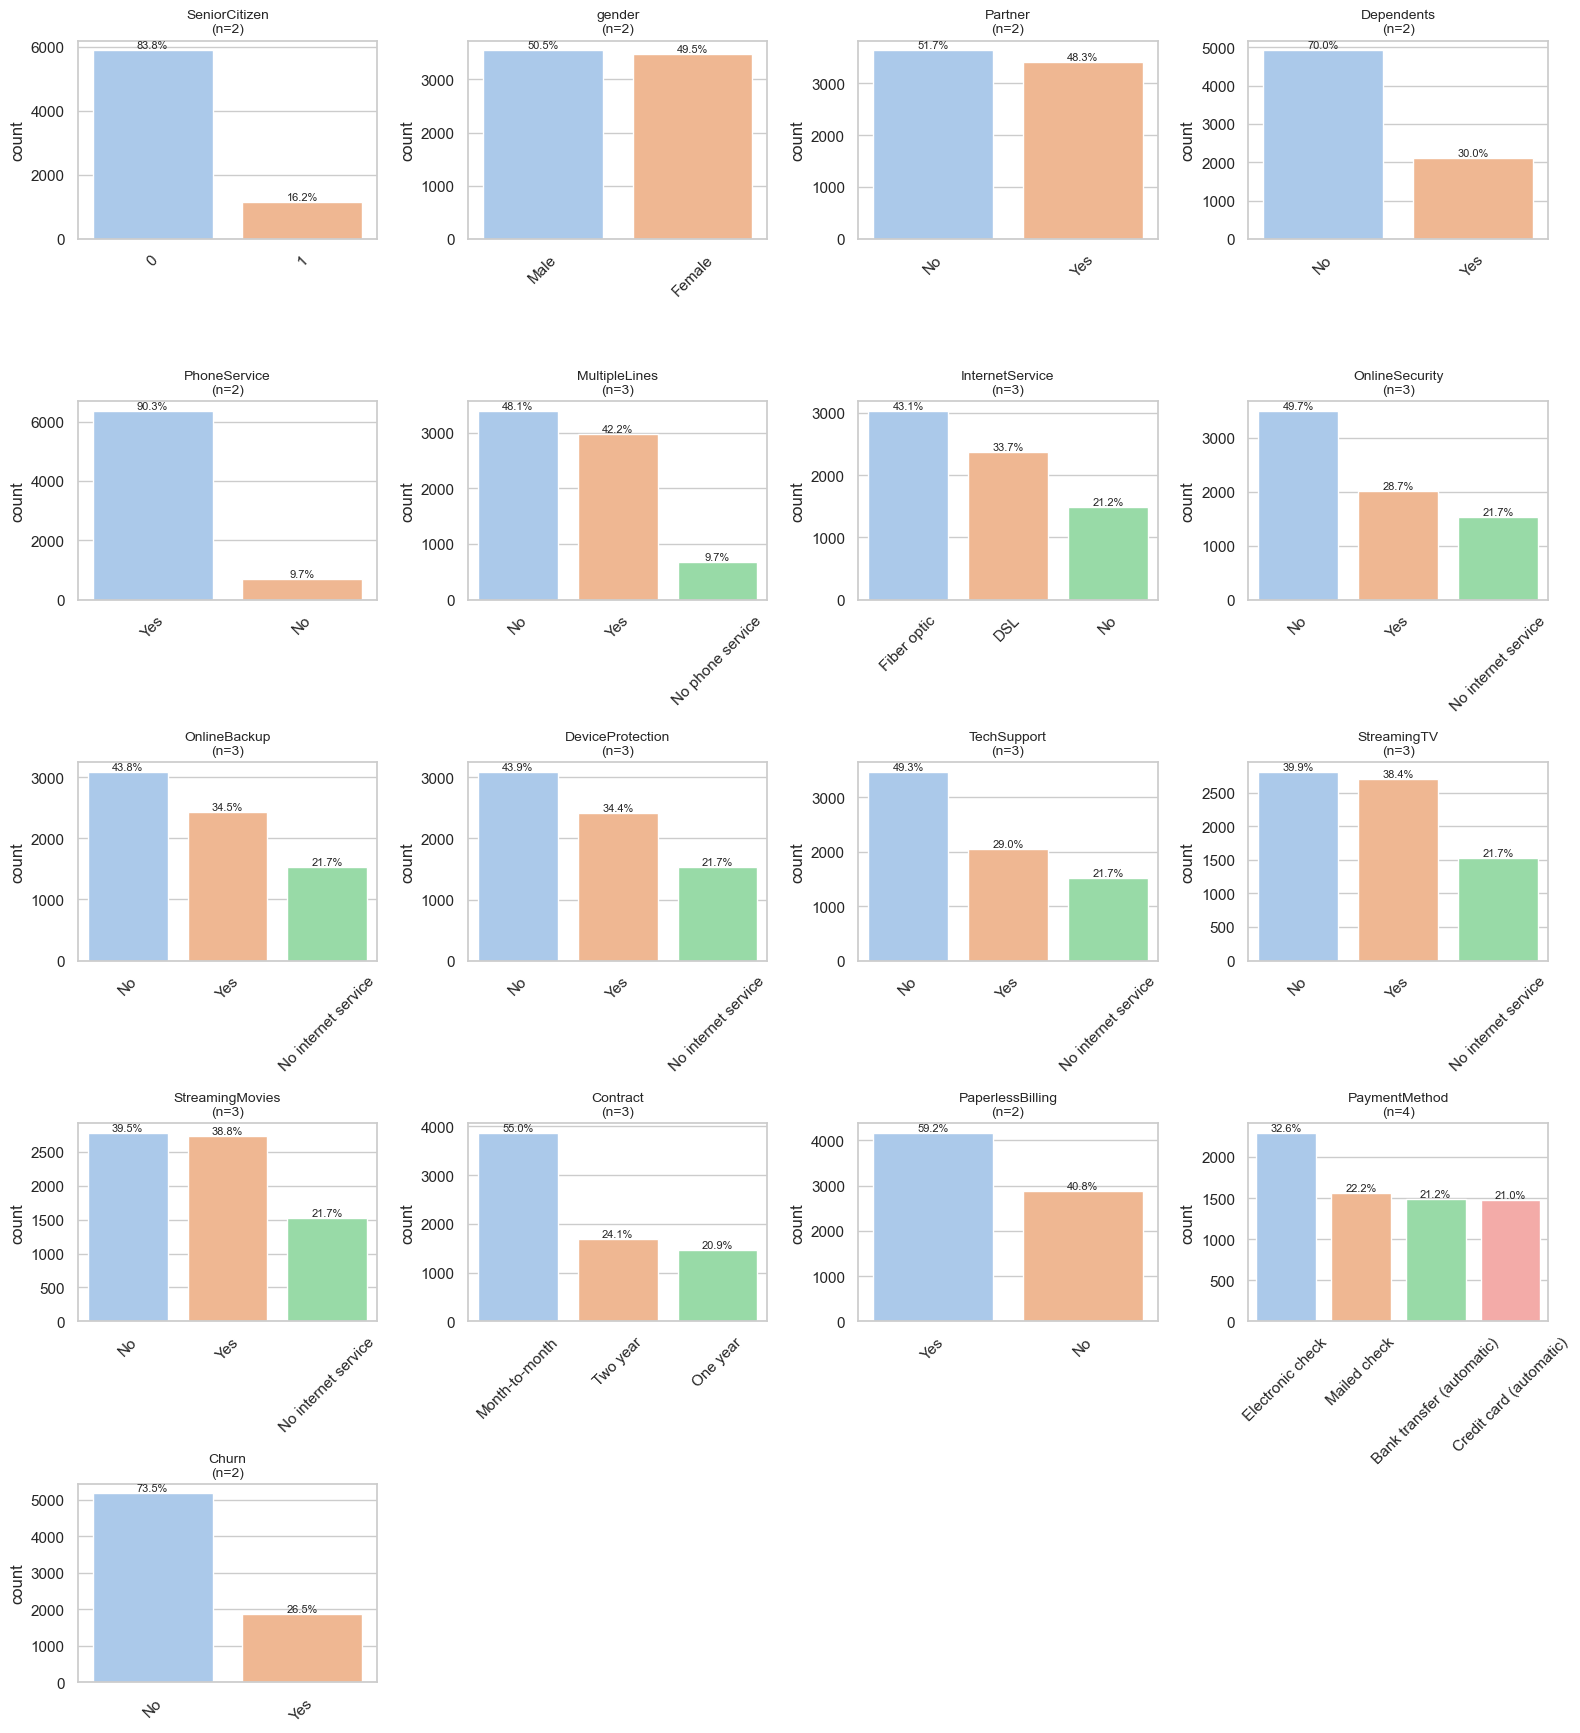


[SeniorCitizen]


,개수,비율
SeniorCitizen,,
0,5901,0.838
1,1142,0.162



[gender]


,개수,비율
gender,,
Male,3555,0.505
Female,3488,0.495



[Partner]


...

,개수,비율
PaperlessBilling,,
Yes,4171,0.592
No,2872,0.408



[PaymentMethod]


,개수,비율
PaymentMethod,,
Electronic check,2296,0.326
Mailed check,1566,0.222
Bank transfer (automatic),1494,0.212
Credit card (automatic),1476,0.210



[Churn]


,개수,비율
Churn,,
No,5174,0.735
Yes,1869,0.265


In [36]:
# 범주형 컬럼 (타겟 포함 여부는 선택)
plot_cat_cols = [c for c in cat_cols]  # Churn 포함

n_cols = 4
n_rows = int(np.ceil(len(plot_cat_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(plot_cat_cols):
    ax = axes[i]
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, palette="pastel")
    ax.set_title(f"{col}\n(n={df[col].nunique()})", fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    
    # 막대 위 비율 표시
    total = len(df)
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f"{height/total:.1%}",
                    (p.get_x() + p.get_width()/2, height),
                    ha="center", va="bottom", fontsize=8)

# 빈 subplot 숨기기
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# 표로도 정리 (개수 + 비율)
for col in plot_cat_cols:
    print(f"\n[{col}]")
    display(df[col].value_counts().to_frame("개수")
            .assign(비율=lambda x: (x["개수"] / len(df)).round(3)))

수치형 변수: ['tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\3373564801.py:29: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\3373564801.py:29: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\3373564801.py:29: UserWarning: Glyph 54805 (\N{HANGUL SYLLABLE HYEONG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\3373564801.py:29: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\3373564801.py:29: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\3373564801.py:29: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) Arial.
  plt.tight

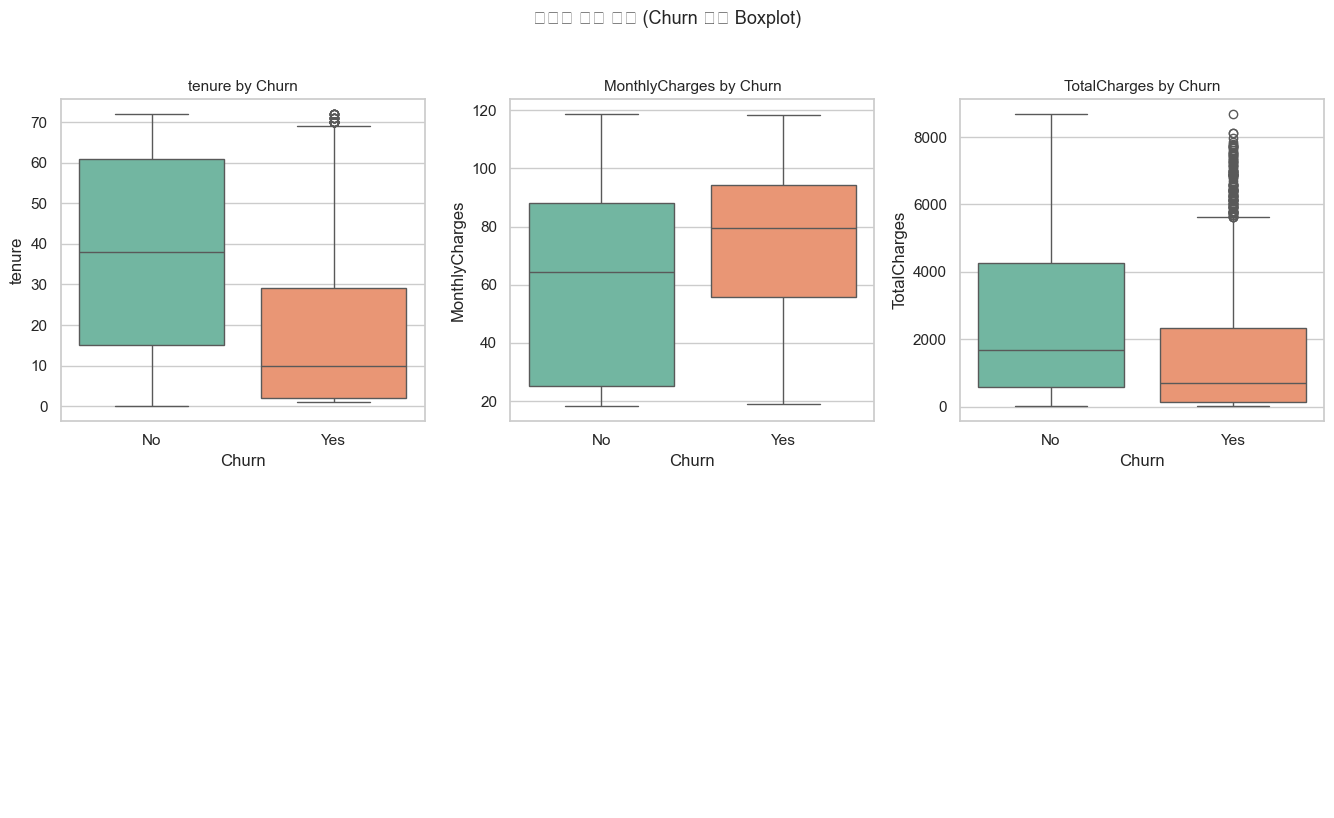

In [37]:
# TotalCharges가 object면 먼저 변환 (이전 셀에서 안 했다면)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

TARGET = "Churn"

# 수치형 변수 (SeniorCitizen은 범주형으로 취급)
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != "SeniorCitizen"]
print("수치형 변수:", num_cols)

n = len(num_cols)
fig, axes = plt.subplots(2, n, figsize=(4.5 * n, 8))

# 1행: Churn 기준 boxplot
for i, col in enumerate(num_cols):
    sns.boxplot(
        data=df, x=TARGET, y=col,
        hue=TARGET, palette="Set2",
        ax=axes[0, i], legend=False
    )
    axes[0, i].set_title(f"{col} by {TARGET}", fontsize=11)
    axes[0, i].set_xlabel(TARGET)
    axes[0, i].set_ylabel(col)

# 2행: 비워두기 (요청하신 2×n 레이아웃 유지)
for j in range(n):
    axes[1, j].axis("off")

plt.suptitle("수치형 변수 분포 (Churn 기준 Boxplot)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**[과제]** 써니는 EDA를 통해 전처리가 필요한 부분을 발견했습니다. AI와 상의하여 관련 코드를 작성하고 분석해보세요.

> Tip: 'Churn' 변수의 타입이나 값 표기 방식

In [38]:
# 원본 보존 + Churn만 0/1 변환
df_churn = df.copy()

# Yes=1(이탈), No=0(유지)
df_churn["Churn"] = df_churn["Churn"].map({"No": 0, "Yes": 1})

# 확인
print("원본 df Churn dtype:", df["Churn"].dtype)
print("원본 df Churn 샘플:", df["Churn"].head(3).tolist())

print("\n변환 df_churn Churn dtype:", df_churn["Churn"].dtype)
print("변환 df_churn Churn 분포:")
print(df_churn["Churn"].value_counts().sort_index())
print(df_churn["Churn"].value_counts(normalize=True).round(3))

원본 df Churn dtype: object
원본 df Churn 샘플: ['No', 'No', 'Yes']

변환 df_churn Churn dtype: int64
변환 df_churn Churn 분포:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


### 1-2) 결측치 현황 파악

**[과제]** 써니는 데이터에 결측치가 존재하는지, 존재한다면 어떤 형태로 얼마나 있는지 궁금해졌습니다. AI와 상의하여 관련 코드를 작성하고 분석해보세요.

In [39]:
# 결측 전처리가 반영된 df_churn 기준
df_miss = df_churn.copy()
df_miss = df_miss.replace(r"^\s*$", np.nan, regex=True)
df_miss["TotalCharges"] = pd.to_numeric(df_miss["TotalCharges"], errors="coerce")

# 행별 결측 개수
row_missing = df_miss.isna().sum(axis=1)

# 1) 요약 테이블
row_missing_table = (
    row_missing.value_counts()
    .sort_index()
    .rename_axis("행당 결측 개수")
    .reset_index(name="행 개수")
)
row_missing_table["비율(%)"] = (row_missing_table["행 개수"] / len(df_miss) * 100).round(2)
display(row_missing_table)

print(f"결측 0개 행: {(row_missing == 0).sum():,}")
print(f"결측 1개 이상 행: {(row_missing >= 1).sum():,}")
print(f"결측 3개 이상 행: {(row_missing >= 3).sum():,}")

,행당 결측 개수,행 개수,비율(%)
0,0,6280,89.17
1,1,742,10.54
2,2,21,0.30


결측 0개 행: 6,280
결측 1개 이상 행: 763
결측 3개 이상 행: 0


C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\2501735828.py:13: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\2501735828.py:13: UserWarning: Glyph 45817 (\N{HANGUL SYLLABLE DANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\2501735828.py:13: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\2501735828.py:13: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\2501735828.py:13: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_13144\2501735828.py:13: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) Arial.
  plt.ti

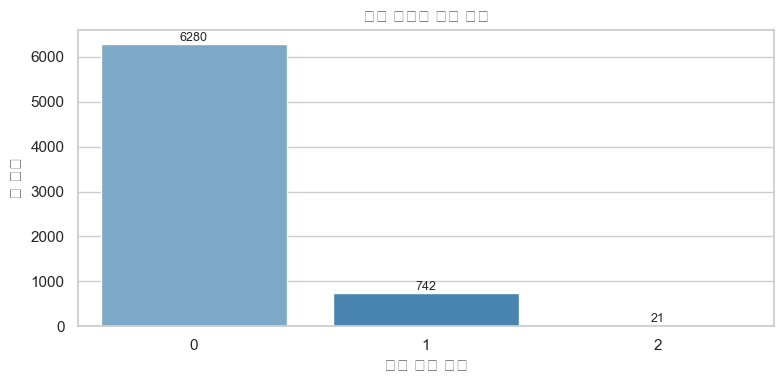

In [40]:
# 2) 히스토그램
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=row_missing, ax=ax, palette="Blues_d")
ax.set_title("행당 결측치 개수 분포")
ax.set_xlabel("행당 결측 개수")
ax.set_ylabel("행 개수")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}", (p.get_x() + p.get_width()/2, h),
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

In [41]:
# 3) 어떤 변수 조합으로 결측이 몰리는지
key_cols = ["tenure", "MonthlyCharges", "PaymentMethod", "InternetService", "TotalCharges"]

pattern = df_miss[key_cols].isna().astype(int)
pattern["pattern"] = pattern.apply(
    lambda r: ", ".join([c for c in key_cols if r[c] == 1]) or "결측 없음",
    axis=1
)

pattern_summary = (
    pattern["pattern"]
    .value_counts()
    .reset_index()
)
pattern_summary.columns = ["결측 변수 조합", "행 개수"]
pattern_summary["비율(%)"] = (pattern_summary["행 개수"] / len(df_miss) * 100).round(2)
display(pattern_summary.head(10))

,결측 변수 조합,행 개수,비율(%)
0,결측 없음,6280,89.17
1,PaymentMethod,201,2.85
2,MonthlyCharges,201,2.85
3,tenure,198,2.81
4,InternetService,131,1.86
5,TotalCharges,11,0.16
6,"tenure, PaymentMethod",7,0.10
7,"MonthlyCharges, InternetService",5,0.07
8,"tenure, InternetService",3,0.04
9,"tenure, MonthlyCharges",3,0.04


In [42]:
# 4) 삭제 전 Churn 비율 영향 확인 (중요!)
for n in [1, 2, 3]:
    mask = row_missing >= n
    if mask.sum() == 0:
        continue
    print(f"\n[결측 {n}개 이상 행] {mask.sum()}개")
    display(
        df_miss.loc[mask, "Churn"]
        .value_counts(normalize=True)
        .mul(100).round(2)
        .to_frame("비율(%)")
    )


[결측 1개 이상 행] 763개


,비율(%)
Churn,
0,73.39
1,26.61



[결측 2개 이상 행] 21개


,비율(%)
Churn,
0,57.14
1,42.86


### 1-3) 클래스 불균형 확인

**[과제]** 써니는 Churn 비율이 얼마나 불균형한지 궁금해졌습니다. AI와 상의하여 관련 코드를 작성하고 분석해보세요.

In [43]:
TARGET = "Churn"

# 클래스별 개수·비율 테이블
churn_table = (
    df_churn[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis("Churn")
    .reset_index(name="개수")
)

churn_table["비율(%)"] = (churn_table["개수"] / len(df_churn) * 100).round(2)
churn_table["라벨"] = churn_table["Churn"].map({0: "No (유지)", 1: "Yes (이탈)"})

# 보기 좋게 컬럼 순서 정리
churn_table = churn_table[["Churn", "라벨", "개수", "비율(%)"]]

display(churn_table)

# 전체 요약
print(f"전체 샘플 수: {len(df_churn):,}")
print(f"불균형 비율 (No:Yes) ≈ {churn_table.loc[churn_table['Churn']==0, '개수'].values[0]} : {churn_table.loc[churn_table['Churn']==1, '개수'].values[0]}")

,Churn,라벨,개수,비율(%)
0,0,No (유지),5174,73.46
1,1,Yes (이탈),1869,26.54


전체 샘플 수: 7,043
불균형 비율 (No:Yes) ≈ 5174 : 1869


### 1-4) 이상치 후보 탐색

**[과제]** 써니는 수치형 변수에 이상치가 있는지 궁금해졌습니다. AI와 상의하여 관련 코드를 작성하고 분석해보세요.

In [44]:
TARGET = "Churn"
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

outlier_by_churn = []

for churn_val in [0, 1]:
    label = "No (유지)" if churn_val == 0 else "Yes (이탈)"
    sub = df_churn[df_churn[TARGET] == churn_val]

    for col in num_cols:
        q1, q3 = sub[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (sub[col] < lower) | (sub[col] > upper)

        outlier_by_churn.append({
            "Churn": churn_val,
            "라벨": label,
            "변수": col,
            "클래스 샘플 수": len(sub),
            "이상치 개수": mask.sum(),
            "이상치 비율(%)": round(mask.mean() * 100, 2),
            "하한": round(lower, 2),
            "상한": round(upper, 2),
        })

display(pd.DataFrame(outlier_by_churn))

,Churn,라벨,변수,클래스 샘플 수,이상치 개수,이상치 비율(%),하한,상한
0,0,No (유지),tenure,5174,0,0.00,-54.00,130.00
1,0,No (유지),MonthlyCharges,5174,0,0.00,-69.55,182.85
2,0,No (유지),TotalCharges,5174,0,0.00,-4951.63,9793.58
3,1,Yes (이탈),tenure,1869,23,1.23,-38.50,69.50
4,1,Yes (이탈),MonthlyCharges,1869,0,0.00,-1.55,151.65
5,1,Yes (이탈),TotalCharges,1869,109,5.83,-3160.70,5626.50


## 2) 결측치 처리

**[과제]** 써니는 데이터셋에 존재하는 결측치를 제거하거나 대치하려 합니다.

이때 변수마다 분포나 특성이 다르면 적합한 대치법도 달라질 수 있다고 생각합니다.

AI와 상의하여 변수별로 제거와 대치 중 어떤 방법이 적합한지 결정하고, 대치를 선택했다면 값 기반, 통계 기반(평균/중앙값/최빈값), 머신러닝 기반(KNN Imputer) 중 어떤 방식이 적합한지 정하여 적용해보세요.

In [45]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

TARGET = "Churn"

# df_churn이 없으면 원본 df에서 생성
if "df_churn" not in globals():
    df_churn = df.copy()
    df_churn[TARGET] = df_churn[TARGET].map({"No": 0, "Yes": 1})

df_clean = df_churn.copy()

# 1) 빈 문자열 → NaN, TotalCharges 숫자 변환
df_clean = df_clean.replace(r"^\s*$", np.nan, regex=True)
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")

print("=== 결측치 처리 전 ===")
print(f"행 수: {len(df_clean):,}")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])


def impute_categorical_group(data, col, group_cols):
    """그룹별 최빈값 → 전역 최빈값 순으로 범주형 결측 대치"""
    for gcol in group_cols:
        if data[col].isna().sum() == 0:
            break
        group_mode = data.groupby(gcol)[col].transform(
            lambda x: x.dropna().mode().iloc[0] if not x.dropna().mode().empty else np.nan
        )
        data[col] = data[col].fillna(group_mode)

    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode().iloc[0])
    return data


# 2) 결측 2개 이상 행 소량 삭제 (Churn 비율 왜곡 최소화)
miss_cols = ["tenure", "MonthlyCharges", "PaymentMethod", "InternetService", "TotalCharges"]
row_miss_count = df_clean[miss_cols].isna().sum(axis=1)
drop_mask = row_miss_count >= 2

print(f"\n결측 2개 이상 행: {drop_mask.sum()}개 삭제")
if drop_mask.sum() > 0:
    print("삭제 대상 Churn=1 비율:", df_clean.loc[drop_mask, TARGET].mean())
    df_clean = df_clean.loc[~drop_mask].copy()

# 3) 범주형: 그룹별 최빈값 대치
df_clean = impute_categorical_group(df_clean, "PaymentMethod", ["Contract", "PaperlessBilling"])
df_clean = impute_categorical_group(df_clean, "InternetService", ["PhoneService"])

# 4) TotalCharges: 도메인 대치 (tenure × MonthlyCharges)
tc_mask = df_clean["TotalCharges"].isna()
df_clean.loc[tc_mask, "TotalCharges"] = (
    df_clean.loc[tc_mask, "tenure"] * df_clean.loc[tc_mask, "MonthlyCharges"]
)
# tenure=0 등 남은 경우 MonthlyCharges로 보완
tc_mask = df_clean["TotalCharges"].isna()
df_clean.loc[tc_mask, "TotalCharges"] = df_clean.loc[tc_mask, "MonthlyCharges"]

# 5) 수치형: KNN Imputer (스케일링 후 적용)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
knn_imputer = KNNImputer(n_neighbors=5)

X_scaled = scaler.fit_transform(df_clean[num_cols])
X_imputed = knn_imputer.fit_transform(X_scaled)
df_clean[num_cols] = scaler.inverse_transform(X_imputed)

# 6) 처리 결과 확인
print("\n=== 결측치 처리 후 ===")
print(f"행 수: {len(df_clean):,}")
remaining = df_clean.isna().sum()
print(f"남은 결측치 총 개수: {remaining.sum()}")
if remaining.sum() > 0:
    print(remaining[remaining > 0])
else:
    print("모든 결측치 처리 완료")

print("\nChurn 분포 (처리 후):")
display(
    df_clean[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis("Churn")
    .to_frame("개수")
    .assign(비율=lambda x: (x["개수"] / len(df_clean) * 100).round(2))
)

=== 결측치 처리 전 ===
행 수: 7,043
tenure             211
InternetService    140
PaymentMethod      211
MonthlyCharges     211
TotalCharges        11
dtype: int64

결측 2개 이상 행: 21개 삭제
삭제 대상 Churn=1 비율: 0.42857142857142855

=== 결측치 처리 후 ===
행 수: 7,022
남은 결측치 총 개수: 0
모든 결측치 처리 완료

Churn 분포 (처리 후):


,개수,비율
Churn,,
0,5162,73.51
1,1860,26.49


## 3) 이상치 처리

**[과제]** 써니는 데이터셋에 존재하는 이상치를 제거하고자 합니다.

다만 이탈(Churn) 고객이 실제로는 "정상 범위를 벗어난" 요금 및 이용 패턴을 가진 고객일 수 있다는 점이 마음에 걸립니다. 이상치 제거가 소수 클래스(Churn)를 함께 지워버릴 위험은 없는지 AI와 상의하여 검토하고 안전한 처리 기준을 정해 적용해 보세요.

In [46]:
# 처리하지 않는다.
#다만 다변량에 대해서 이상치 인것만 정리한다.
def count_outlier_cols(data, cols, ref_data=None):
    ref = data if ref_data is None else ref_data
    cnt = pd.Series(0, index=data.index)
    for col in cols:
        q1, q3 = ref[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        cnt += ((data[col] < lower) | (data[col] > upper)).astype(int)
    return cnt

out_cnt = count_outlier_cols(df_clean, num_cols, ref_data=df_clean[df_clean["Churn"]==0])
strict_mask = out_cnt >= 2   # 2개 이상 변수에서 이상치

## 4) 데이터 분할 및 스케일링/인코딩

**[과제]** 써니는 모델 구축 전 학습/테스트 데이터를 나누려고 합니다. 클래스 불균형이 심한 상황에서 어떤 분할 방법이 적합할지 AI와 상의해서 정하고 나눠 보세요.

In [47]:
from sklearn.model_selection import train_test_split

TARGET = "Churn"
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # ★ Churn 비율만 유지
)

In [48]:
def show_churn_ratio(y, name):
    print(f"\n[{name}] n={len(y):,}")
    display(
        y.value_counts(normalize=True).mul(100).round(2).to_frame("비율(%)")
    )

show_churn_ratio(y, "전체")
show_churn_ratio(y_train, "Train")
show_churn_ratio(y_test, "Test")


[전체] n=7,022


,비율(%)
Churn,
0,73.51
1,26.49



[Train] n=5,617


,비율(%)
Churn,
0,73.51
1,26.49



[Test] n=1,405


,비율(%)
Churn,
0,73.52
1,26.48


**[과제]** 써니는 분할한 학습/테스트 데이터에 적절한 스케일링 및 인코딩을 적용하고자 합니다. AI와 상의하여 수치형 변수와 범주형 변수 각각에 적합한 스케일링 및 인코딩 방식을 정하고 적용해보세요.

In [49]:
from sklearn.model_selection import train_test_split

TARGET = "Churn"

# 1) PhoneService + MultipleLines → PhoneLines 파생 (분할 전)
df_model = df_clean.copy()

conditions = [
    df_model["PhoneService"] == "No",
    (df_model["PhoneService"] == "Yes") & (df_model["MultipleLines"] == "No"),
    (df_model["PhoneService"] == "Yes") & (df_model["MultipleLines"] == "Yes"),
]
choices = ["No_phone", "Single_line", "Multiple_lines"]
df_model["PhoneLines"] = np.select(conditions, choices, default="Other")

if (df_model["PhoneLines"] == "Other").any():
    print("⚠️ PhoneLines 예외 행:")
    display(df_model.loc[df_model["PhoneLines"] == "Other", ["PhoneService", "MultipleLines", TARGET]])

df_model = df_model.drop(columns=["PhoneService", "MultipleLines"])
print("PhoneLines 분포:")
print(df_model["PhoneLines"].value_counts())

# 2) X / y 분리
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

# 3) stratify 분할 (Churn 비율 유지)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# 4) 분할 후 Churn 비율 확인
def show_churn_ratio(y_data, name):
    ratio = y_data.value_counts(normalize=True).mul(100).round(2)
    print(f"\n[{name}] n={len(y_data):,}")
    display(ratio.to_frame("비율(%)"))

show_churn_ratio(y, "전체")
show_churn_ratio(y_train, "Train")
show_churn_ratio(y_test, "Test")

PhoneLines 분포:
PhoneLines
Single_line       3379
Multiple_lines    2963
No_phone           680
Name: count, dtype: int64

[전체] n=7,022


,비율(%)
Churn,
0,73.51
1,26.49



[Train] n=5,617


,비율(%)
Churn,
0,73.51
1,26.49



[Test] n=1,405


,비율(%)
Churn,
0,73.52
1,26.48


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 수치형 / 범주형 컬럼 지정
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in X_train.columns if c not in num_cols]

print("수치형:", num_cols)
print("범주형:", cat_cols)

# ColumnTransformer: train fit → test transform
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"\n전처리 후 shape - Train: {X_train_processed.shape}, Test: {X_test_processed.shape}")

# feature 이름 확인 (선택)
cat_feature_names = preprocessor.named_transformers_["cat"].get_feature_names_out(cat_cols)
feature_names = list(num_cols) + list(cat_feature_names)
print(f"총 feature 수: {len(feature_names)}")

수치형: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
범주형: ['gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'PhoneLines']

전처리 후 shape - Train: (5617, 43), Test: (1405, 43)
총 feature 수: 43


## 5) 클래스 불균형 시각화 및 Resampling 적용

**[과제]** 써니는 Churn 여부에 따라 고객들의 데이터가 얼마나 잘 구분되는지 궁금합니다. t-SNE로 학습 데이터를 2차원에 시각화하여 두 클래스가 얼마나 겹쳐 있는지 AI와 함께 코드를 작성하고 분석해보세요.

In [51]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# t-SNE 입력: 전처리된 학습 데이터
X_tsne_input = X_train_processed
y_tsne = y_train.reset_index(drop=True)

# t-SNE (2차원)
tsne = TSNE(
    n_components=2,
    perplexity=30,        # 5~50 사이 조정 가능 (데이터 크기에 따라)
    learning_rate="auto",
    init="pca",
    random_state=42,
    max_iter=1000,
)
X_tsne = tsne.fit_transform(X_tsne_input)

# 시각화용 DataFrame
tsne_df = pd.DataFrame({
    "TSNE_1": X_tsne[:, 0],
    "TSNE_2": X_tsne[:, 1],
    "Churn": y_tsne.map({0: "No (유지)", 1: "Yes (이탈)"}),
})

# 산점도
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tsne_df,
    x="TSNE_1",
    y="TSNE_2",
    hue="Churn",
    palette={"No (유지)": "#4C72B0", "Yes (이탈)": "#DD8452"},
    alpha=0.6,
    s=25,
    edgecolor=None,
)
plt.title("t-SNE: Train 데이터 Churn 클래스 분포 (2D)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Churn", loc="best")
plt.tight_layout()
plt.show()

# 클래스별 샘플 수
print("Train 클래스 분포:")
display(tsne_df["Churn"].value_counts().to_frame("개수"))

KeyboardInterrupt: 

t-SNE 시각화 결과, Churn=0(유지)과 Churn=1(이탈)이 대부분 영역에서 겹쳐 나타났다. 이는 현재 변수만으로 두 클래스가 선형적으로 잘 분리되지 않음을 시사한다. 또한 No 클래스 비중이 높아 소수 클래스인 Yes가 전체 분포 안에 흩어져 보인다. 따라서 이후 SMOTE 등 리샘플링과 비선형 모델 적용, 이탈 클래스 중심 평가 지표가 필요하다.

**[과제]** 써니는 클래스 불균형을 완화하기 위해 여러 Resampling 기법(TomekLinks, SMOTE, SMOTE+TomekLinks, ADASYN)을 학습 데이터에 적용해보고 t-SNE로 데이터 분포가 어떻게 변하는지 궁금해졌습니다. AI와 함께 관련 코드를 작성하고 분석해보세요.

> Tip: Resampling은 학습 데이터에만 적용하고, 테스트 데이터는 원본 그대로 유지할 것

In [52]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from scipy.sparse import issparse
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, make_scorer
from xgboost import XGBClassifier

from imblearn.under_sampling import TomekLinks
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

# dense 변환
X_tr = X_train_processed.toarray() if issparse(X_train_processed) else X_train_processed.copy()
y_tr = y_train.copy()

min_count = y_tr.value_counts().min()
k_candidates = [k for k in [3, 5, 7] if k <= min_count - 1]
print(f"k_neighbors 후보: {k_candidates}")

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
f1_pos = make_scorer(f1_score, pos_label=1)

clf = XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.1,
    eval_metric="logloss", random_state=42, n_jobs=-1,
)

def make_sampler(method, params=None):
    params = params or {}
    if method == "TomekLinks":
        return TomekLinks(sampling_strategy="auto")
    if method == "SMOTE":
        return SMOTE(k_neighbors=params.get("k_neighbors", 5), random_state=42)
    if method == "SMOTE+TomekLinks":
        k = params.get("k_neighbors", 5)
        return SMOTETomek(smote=SMOTE(k_neighbors=k, random_state=42), random_state=42)
    if method == "ADASYN":
        return ADASYN(n_neighbors=params.get("n_neighbors", 5), random_state=42)
    raise ValueError(method)

sampler_configs = {
    "TomekLinks": {"param_grid": [{}]},
    "SMOTE": {"param_grid": [{"k_neighbors": k} for k in k_candidates]},
    "SMOTE+TomekLinks": {"param_grid": [{"k_neighbors": k} for k in k_candidates]},
    "ADASYN": {"param_grid": [{"n_neighbors": k} for k in k_candidates]},
}

best_params = {}
cv_results = []

for name, cfg in sampler_configs.items():
    best_score, best_param = -1, cfg["param_grid"][0]

    for params in cfg["param_grid"]:
        sampler = make_sampler(name, params)
        pipe = ImbPipeline([
            ("sampler", sampler),
            ("clf", clone(clf)),
        ])  # ★ pipe = 반드시 할당

        scores = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring=f1_pos, n_jobs=-1)
        mean_f1 = scores.mean()

        cv_results.append({
            "Method": name,
            "Params": str(params) if params else "default",
            "CV_F1_Churn1": round(mean_f1, 4),
            "CV_std": round(scores.std(), 4),
        })

        if mean_f1 > best_score:
            best_score, best_param = mean_f1, params

    best_params[name] = best_param
    print(f"[{name}] best CV F1(Churn=1)={best_score:.4f}, params={best_param}")

cv_result_df = pd.DataFrame(cv_results)
display(cv_result_df)

# 리샘플링 데이터셋 구성
resampled_datasets = {"Before": (X_tr, y_tr)}
summary_rows = []

for name in sampler_configs:
    sampler = make_sampler(name, best_params[name])
    X_res, y_res = sampler.fit_resample(X_tr, y_tr)
    resampled_datasets[name] = (X_res, y_res)

    summary_rows.append({
        "Method": name,
        "Best_Params": str(best_params[name]) if best_params[name] else "default",
        "Train_Size": len(y_res),
        "Churn=0": (y_res == 0).sum(),
        "Churn=1": (y_res == 1).sum(),
        "Churn1_Ratio(%)": round((y_res == 1).mean() * 100, 2),
    })

display(pd.DataFrame(summary_rows))

best_overall = cv_result_df.groupby("Method")["CV_F1_Churn1"].max().idxmax()
X_train_best, y_train_best = resampled_datasets[best_overall]
print(f"★ 최적 리샘플링: {best_overall}, shape={X_train_best.shape}")

k_neighbors 후보: [3, 5, 7]
[TomekLinks] best CV F1(Churn=1)=0.6022, params={}
[SMOTE] best CV F1(Churn=1)=0.6190, params={'k_neighbors': 3}
[SMOTE+TomekLinks] best CV F1(Churn=1)=0.6178, params={'k_neighbors': 5}
[ADASYN] best CV F1(Churn=1)=0.6134, params={'n_neighbors': 5}


,Method,Params,CV_F1_Churn1,CV_std
0,TomekLinks,default,0.6022,0.0084
1,SMOTE,{'k_neighbors': 3},0.6190,0.0034
2,SMOTE,{'k_neighbors': 5},0.6133,0.0045
3,SMOTE,{'k_neighbors': 7},0.6074,0.0048
4,SMOTE+TomekLinks,{'k_neighbors': 3},0.6170,0.0041
5,SMOTE+TomekLinks,{'k_neighbors': 5},0.6178,0.0074
6,SMOTE+TomekLinks,{'k_neighbors': 7},0.6160,0.0047
7,ADASYN,{'n_neighbors': 3},0.6105,0.0034
8,ADASYN,{'n_neighbors': 5},0.6134,0.0075
9,ADASYN,{'n_neighbors': 7},0.6113,0.0032


,Method,Best_Params,Train_Size,Churn=0,Churn=1,Churn1_Ratio(%)
0,TomekLinks,default,5237,3749,1488,28.41
1,SMOTE,{'k_neighbors': 3},8258,4129,4129,50.00
2,SMOTE+TomekLinks,{'k_neighbors': 5},7896,3948,3948,50.00
3,ADASYN,{'n_neighbors': 5},8177,4129,4048,49.50


★ 최적 리샘플링: SMOTE, shape=(8258, 43)


**[과제]** 써니는 Resampling 기법별로 분류 모델(예: XGBoost)을 학습시켜 성능을 비교하려고 합니다. AI와 상의하여 관련 코드를 작성하고 분석해보세요.

In [54]:
from scipy.sparse import issparse
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, make_scorer,
)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings("ignore")

# 테스트 데이터 (리샘플링 X)
X_te = X_test_processed.toarray() if issparse(X_test_processed) else X_test_processed.copy()

# 평가: Churn=1(이탈) F1
f1_churn1 = make_scorer(f1_score, pos_label=1)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# XGBoost 하이퍼파라미터 탐색 범위
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3],
}

results = []
trained_models = {}

for name, (X_s, y_s) in resampled_datasets.items():
    print(f"\n{'='*55}")
    print(f"[{name}] 학습 데이터: {X_s.shape}, Churn=1 비율: {(y_s==1).mean():.2%}")

    # 클래스 비율 반영 (Before/TomekLinks 등 under 쪽에 유리)
    scale_pos_weight = (y_s == 0).sum() / max((y_s == 1).sum(), 1)

    xgb = XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        scale_pos_weight=scale_pos_weight,
    )

    # 방법별 XGBoost 최적화
    grid = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        cv=cv,
        scoring=f1_churn1,
        n_jobs=-1,
        verbose=0,
    )
    grid.fit(X_s, y_s)

    best_model = grid.best_estimator_
    trained_models[name] = best_model
    y_pred = best_model.predict(X_te)

    results.append({
        "Resampling": name,
        "CV_Best_F1_Churn1": round(grid.best_score_, 4),
        "Test_Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test_Precision_Churn1": round(precision_score(y_test, y_pred, pos_label=1, zero_division=0), 4),
        "Test_Recall_Churn1": round(recall_score(y_test, y_pred, pos_label=1, zero_division=0), 4),
        "Test_F1_Churn1": round(f1_score(y_test, y_pred, pos_label=1, zero_division=0), 4),
        "Best_Params": str(grid.best_params_),
    })

    print(f"Best CV F1(Churn=1): {grid.best_score_:.4f}")
    print(f"Best params: {grid.best_params_}")
    print(classification_report(y_test, y_pred, target_names=["No(0)", "Yes(1)"]))

# 성능 비교 테이블
results_df = (
    pd.DataFrame(results)
    .sort_values("Test_F1_Churn1", ascending=False)
    .reset_index(drop=True)
)
display(results_df)


[Before] 학습 데이터: (5617, 43), Churn=1 비율: 26.49%
Best CV F1(Churn=1): 0.6323
Best params: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 0.8}
              precision    recall  f1-score   support

       No(0)       0.91      0.75      0.82      1033
      Yes(1)       0.54      0.80      0.64       372

    accuracy                           0.76      1405
   macro avg       0.72      0.78      0.73      1405
weighted avg       0.81      0.76      0.78      1405


[TomekLinks] 학습 데이터: (5237, 43), Churn=1 비율: 28.41%
Best CV F1(Churn=1): 0.6787
Best params: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 0.8}
              precision    recall  f1-score   support

       No(0)       0.91      0.75      0.82      1033
      Yes(1)       0.53      0.79      0.63       372

    accuracy                           0.76      1405
   macro avg     

,Resampling,CV_Best_F1_Churn1,Test_Accuracy,Test_Precision_Churn1,Test_Recall_Churn1,Test_F1_Churn1,Best_Params
0,Before,0.6323,0.7637,0.5360,0.8011,0.6422,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
1,TomekLinks,0.6787,0.7601,0.5318,0.7876,0.6349,"{'colsample_bytree': 1.0, 'learning_rate': 0.0..."
2,SMOTE+TomekLinks,0.8721,0.7943,0.6030,0.6532,0.6271,"{'colsample_bytree': 1.0, 'learning_rate': 0.0..."
3,SMOTE,0.8541,0.7836,0.5806,0.6586,0.6171,"{'colsample_bytree': 0.8, 'learning_rate': 0.1..."
4,ADASYN,0.8496,0.7836,0.5821,0.6478,0.6132,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."


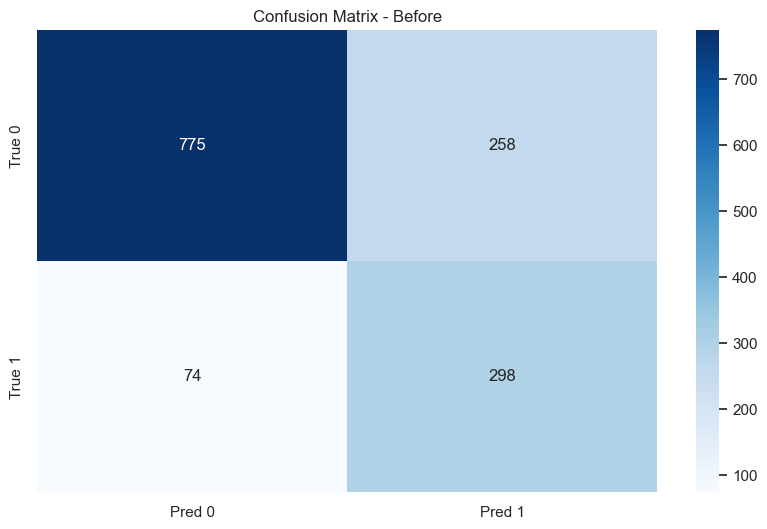

In [55]:
best_name = results_df.loc[0, "Resampling"]
y_pred_best = trained_models[best_name].predict(X_te)

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred 0", "Pred 1"],
            yticklabels=["True 0", "True 1"])
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

## 6) SVDD (One-Class SVM) 적용

**[과제]** 써니는 Resampling 방식 대신, 정상(Non-Churn) 데이터만으로 정상 영역을 학습하는 One-Class Learning 접근은 성능이 어떨지 궁금해졌습니다. AI와 함께 One-Class SVM(SVDD)을 정상 데이터로만 학습시키고 Churn 샘플이 그 경계 밖으로 얼마나 잘 걸러지는지 코드를 작성하고 분석해보세요.

> Tip: 정상 데이터로만 학습하고 테스트는 정상/이상 모두 진행

**[과제]** 써니는 `nu` 값에 따라 SVDD의 경계와 성능이 어떻게 달라지는지 궁금해졌습니다. AI와 함께 관련 코드를 작성하고 분석해보세요.

## 7) 모델 결과 분석 및 비교

**[과제]** 써니는 지금까지 클래스 불균형 해결을 위해 시도한 Resampling과 One-Class Learning 중, 이 이탈 탐지 문제에는 어떤 접근이 더 적합한지 판단하고자 합니다. AI와 함께 두 접근의 성능을 한 표에 정리하고 어떤 상황에서 어떤 방법이 유리한지 인사이트를 도출해 보세요.